![Banner](../../../../Images/Banner/07_remote_sensing/09_03_banner_rs_rader.png)


# RADARSAT GRD Data

RADARSAT GRD (Ground Range Detected) Data is a standardized radar image product from the RADARSAT satellite series, where the radar signal intensity has been geometrically corrected and processed into a user-friendly image.


## Overview

This type of data provides calibrated backscatter values referenced to a map projection, making it easier to use for analysis of surface properties, land cover, and change detection. GRD products are particularly useful because they are ready for interpretation and integration with other geospatial datasets in GIS or remote sensing applications.


## Core concepts

### Learning objectives

1. Open an RCM Level-1 GRD product from product.xml and subset the imagery to an area of interest.
2. Remove the ScanSAR noise-equivalent sigma-zero floor and calibrate digital numbers to sigma-nought with the range LUT.
3. Choose beta-nought, sigma-nought, or gamma-nought for the terrain and the analysis that follows.
4. Multilook and speckle-filter calibrated backscatter, and measure the change in equivalent number of looks.
5. Describe radiometric terrain flattening and range-Doppler geocoding, including layover, shadow, and local incidence angle.
6. Geocode the Cox's Bazar RCM scene from its ground control points and state the accuracy limit of that DEM-free warp.
7. Convert linear sigma-nought to decibels for display, and keep averages and filters in linear units.

### Contents

1. Backscatter workflow, step by step
2. Real-data example: Cox's Bazar -- Teknaf coast, Bangladesh
3. Takeaways and limitations


## Backscatter workflow, step by step

**Step 1, Read and subset**
- Open `product.xml` in SNAP, not the TIFF. The TIFF alone has no radar geometry.
- Subset to your AOI immediately. RCM scenes are large, and every later step scales with the number of pixels.

**Step 2, Thermal noise removal**
- The sensor adds a noise floor, the NESZ (noise-equivalent sigma zero). It is roughly −20 to −25 dB, depending on beam.
- Low-backscatter targets sit near this floor: calm water, smooth roads, and especially cross-pol HV over bare soil.
- Subtracting the noise level from the `calibration/` folder prevents false brightness and visible beam seams.

**Step 3, Radiometric calibration**
- This converts digital numbers (DN) into physically meaningful backscatter:

  **σ⁰ (or β⁰, γ⁰) = (DN² + B) / A**

  - *A* is the range-dependent gain from `lutSigma`, `lutBeta`, or `lutGamma`. It is interpolated across columns from `pixelFirstLutValue` and `stepSize`.
  - *B* is the offset.
- Which one to choose:
  - **β⁰** is radar brightness in slant geometry. It is the required input for terrain flattening.
  - **σ⁰** is normalized to the ellipsoid ground area. It is fine for flat terrain.
  - **γ⁰** is normalized to the area perpendicular to the beam. It is less incidence-angle dependent.
- For complex data (SLC), calibrate I and Q separately so the phase is preserved: divide by √A.

**Step 4, Multilooking (optional)**
- This averages pixels in range and azimuth to get roughly square ground pixels.
- It reduces speckle, at the cost of resolution.
- An example is averaging 2×2 on 16 m data to get a clean 30 m product.

**Step 5, Speckle filtering**
- Speckle is multiplicative noise inherent to coherent imaging.

| Filter | Character | When |
|---|---|---|
| Boxcar | Simple mean, blurs edges | Polarimetric matrices, large homogeneous areas |
| Lee / Refined Lee | Adaptive, preserves edges | General land mapping (default choice) |
| Gamma-MAP | Statistical model | Agriculture, forests |
| Lee Sigma | Preserves point targets | Urban, ships |
| Multi-temporal (Quegan) | Uses the stack over time | Time series; best detail retention |

- Use a 5×5 or 7×7 window.
- Do **not** filter before InSAR coregistration, because it destroys phase.
- Avoid heavy filtering before ship or point-target detection.

**Step 6, Radiometric terrain flattening**
- Slopes facing the sensor appear bright, and slopes facing away appear dark, purely from geometry.
- Terrain flattening (Small 2011) uses a DEM to compute the true illuminated area. It converts β⁰ into **terrain-flattened γ⁰ (γ⁰_T)**.
- It is essential in hilly or mountainous areas and for comparing ascending with descending passes.
- In flat agricultural plains it changes little.

**Step 7, Terrain correction (geocoding / orthorectification)**
- Range-Doppler terrain correction uses the orbit, timing, and a DEM to place each pixel at its true map location. This removes foreshortening displacement.
- Settings:
  - **DEM:** Copernicus GLO-30. SRTM 1-sec also works; use a local LiDAR DEM if available.
  - **Resampling:** bilinear for intensity. Nearest neighbour for masks or classes.
  - **Output pixel size:** match the beam mode (e.g., 30 m for 30M CP).
  - **Projection:** UTM or a national grid.
- Also export the **layover/shadow mask**, the **local incidence angle**, and the **projected local incidence angle**. They are critical for quality control and as model covariates.

**Step 8, Convert to dB**
- **dB = 10·log₁₀(σ⁰)**
- Do statistics (averaging, filtering) in **linear** units, and use dB only for display and for ML features. Averaging dB values biases the result.

**Step 9, Quality control**
- Mask pixels flagged as layover or shadow.
- Mask pixels near the noise floor.
- Mask image edges that have no-data artifacts.
- Check radiometric stability against known stable targets. Urban areas and dense forest should stay near-constant over time.


## Real-data example: Cox's Bazar -- Teknaf coast, Bangladesh

This runs the backscatter workflow above on a real **RCM-1 Level-1 GRD** product: beam mode
**SCLND** (ScanSAR Low Noise, ~100 m resolution, 350 km swath), VV+VH, acquired
**2023-10-25**, cached locally at
`Data/08_remote_sensing/08_03_radar/RCM1_OK2801594_PK2803067_1_SCLND_20231025_120938_VV_VH_GRD/`. The AOI is the same
Cox's Bazar -- Teknaf box used throughout this tutorial series
(`07_03_01_01_sentinel1_grd.ipynb`, `07_03_01_07_DualPol.ipynb`), so the same stretch of
coastline can be compared across a Sentinel-1 IW scene and this wide-swath RCM ScanSAR scene.

The product ships exactly what Steps 1-3 need:

```
RCM1_..._GRD/
├── imagery/2803067_1_VV.tif, 2803067_1_VH.tif   # raw DN, GCP-georeferenced only
├── metadata/product.xml                          # sensor, beam, pass, pixel spacing
└── metadata/calibration/
    ├── lutSigma_VV.xml, lutSigma_VH.xml          # Step 3: range-only calibration gain
    └── noiseLevels_VV.xml, noiseLevels_VH.xml    # Step 2: per-beam NESZ (ScanSAR stitches 8 sub-beams)
```

Like the raw Sentinel-1 GRD source in `07_03_01_01`, the imagery carries only GCPs (no map CRS
or transform yet) -- `product.xml`'s own geolocation grid and orbit state vectors are in RCM's
own schema, which `geolattice` does not parse (a gap called out plainly, not hidden, when Steps 6-7
come up below).


**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Set up imports, load product metadata, and print a one-line sanity check that this really
# is the RCM scene (sensor, beam mode, polarizations, pass, time, pixel spacing) described above.

# 1. Silence warnings (GDAL/rasterio emit GCP-related warnings for this GCP-only product)
#    so the notebook's printed output stays readable.
import warnings
warnings.filterwarnings("ignore")  # hide library warnings

import xml.etree.ElementTree as ET  # XML parsing
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import rasterio  # raster reading
import rasterio.warp as rwarp  # reprojection
import rioxarray  # noqa: F401  (registers the .rio accessor on xarray)
import xarray as xr  # labelled rasters
from rasterio.transform import from_gcps, rowcol  # affine transform from GCPs; map coordinate -> (row, col)

# 2. Pull in the geolattice SAR helpers used throughout: `radarsat` has the RCM-specific LUT and
#    noise-level readers/calibration (Steps 2-3 below), while `sentinel1` (aliased `s1`) and
#    `speckle` are the sensor-generic dB conversion, multilook and speckle-filter routines
#    already used for Sentinel-1 elsewhere in this tutorial series.
from geolattice import rsense as rs
# RCM readers, Sentinel-1 tools and speckle filters
from geolattice.rsense.sar import radarsat, sentinel1 as s1, speckle

plt.rcParams.update({"figure.dpi": 110})  # figure resolution

# 3. Point at the cached RCM-1 GRD product on disk, the Cox's Bazar -- Teknaf AOI shared with
#    the other notebooks in this series, and the two polarizations this scene carries.
PRODUCT = Path("../../../../Data/08_remote_sensing/08_03_radar/RCM1_OK2801594_PK2803067_1_SCLND_20231025_120938_VV_VH_GRD")
AOI = (91.85, 21.30, 92.15, 21.55)        # Cox's Bazar -- Teknaf, Bangladesh (same box as the GRD/DualPol tutorials)
POLS = ("VV", "VH")  # the two polarisations of the product

# 4. Parse product.xml (RCM's own metadata schema, under the "rcmGsProductSchema" namespace)
#    and define a small helper to pull one tag's text out of it by name.
ns = {"r": "rcmGsProductSchema"}
root = ET.parse(PRODUCT / "metadata/product.xml").getroot()  # the product metadata XML


def info(tag):  # read one text field from the metadata
    e = root.find(f".//r:{tag}", ns)  # find the element (with the RCM XML namespace)
    return e.text if e is not None else None  # its text, or None when missing


# 5. Print sensor, beam mode, product type, polarizations, pass direction, acquisition time
#    and pixel spacing as a quick confirmation that this matches the product described above.
print(f"geolattice.rsense {rs.__version__} | {info('satellite')} {info('beamModeMnemonic')} "
      f"{info('productType')}, {info('polarizations')}, {info('passDirection')} pass | "
      f"{info('rawDataStartTime')} | pixel spacing {float(info('sampledPixelSpacing')):.0f} m")

geolattice.rsense 0.2.0.dev0 | RCM-1 SCLND GRD, VH VV, Ascending pass | 2023-10-25T12:09:38.332000Z | pixel spacing 40 m


### Read and subset

Like the raw Sentinel-1 GRD source, this product's GeoTIFFs carry only ground control points
(no map CRS/transform). A GCP-fitted affine (`rasterio.transform.from_gcps`) is accurate
enough over an AOI this size to turn its lon/lat corners into an approximate pixel window,
without reading or warping the whole ~8,900 x 12,900 pixel ScanSAR scene.


In [2]:
# Step 1: read only the AOI sub-window of each full-resolution GeoTIFF, using a GCP-fitted
# affine transform to turn the AOI's lon/lat corners into an approximate pixel window --
# without reading or warping the whole ~8,900 x 12,900 pixel ScanSAR scene.

def read_window(pol):
    with rasterio.open(PRODUCT / f"imagery/2803067_1_{pol}.tif") as src:  # open the image of this polarisation
        # 1. This GeoTIFF carries only ground control points, no map CRS/affine transform,
        #    so grab the GCPs and their CRS directly from the raster.
        gcps, gcp_crs = src.gcps
        # 2. Fit an affine transform from those GCPs. It is only approximate, but accurate
        #    enough over an AOI this size to locate the AOI in pixel space.
        aff = from_gcps(gcps)
        # 3. Map the AOI's four lon/lat corners to row/col using that transform, then take
        #    the bounding min/max (clipped to the image's actual height/width) as the window
        #    to read -- this is the "subset immediately" step of the workflow.
        corners = [(AOI[0], AOI[1]), (AOI[2], AOI[1]), (AOI[0], AOI[3]), (AOI[2], AOI[3])]
        rcs = [rowcol(aff, lon, lat) for lon, lat in corners]  # pixel position of each AOI corner
        rows, cols = [r for r, c in rcs], [c for r, c in rcs]  # rows and columns of the corners
        row0, row1 = max(0, min(rows)), min(src.height, max(rows))  # row range, clipped to the image
        col0, col1 = max(0, min(cols)), min(src.width, max(cols))  # column range, clipped to the image
        # 4. Read only that window of band 1 (raw DN values) rather than the full scene.
        dn = src.read(1, window=((row0, row1), (col0, col1)))
        # 5. Return the DN crop, its window bounds, the full scene width (needed later to
        #    interpolate the range-dependent calibration LUT/noise curves across the whole
        #    swath before slicing them down to this same window), and the GCPs/CRS (needed
        #    later for GCP-based geocoding in Steps 6-7).
        return dn, (row0, row1, col0, col1), src.width, gcps, gcp_crs


# 6. Read the AOI window for both polarizations. The window, full width, and GCPs are the
#    same for VV and VH (identical grid), so it is fine to keep only the last pol's values.
dn = {}
for pol in POLS:  # both polarisations
    dn[pol], WIN, FULL_WIDTH, gcps, gcp_crs = read_window(pol)  # raw DN of the window and its geometry
ROW0, ROW1, COL0, COL1 = WIN  # the window bounds
# 7. Report the crop size, its offset within the full scene, and the raw DN range for each
#    polarization as a quick sanity check before calibration.
print(f"crop: {dn['VV'].shape[0]} x {dn['VV'].shape[1]} pixels, offset (row {ROW0}, col {COL0}) "
      f"of a {FULL_WIDTH}-sample-wide scene | DN range VV {dn['VV'].min()}-{dn['VV'].max()}, "
      f"VH {dn['VH'].min()}-{dn['VH'].max()}")

crop: 809 x 878 pixels, offset (row 8903, col 7420) of a 8942-sample-wide scene | DN range VV 54-22622, VH 22-4119


### Noise removal and radiometric calibration

`read_rcm_lut`/`interpolate_rcm_lut` give the range-only gain curve from `lutSigma_<pol>.xml`;
`read_rcm_noise_levels`/`interpolate_rcm_noise` stitch the ScanSAR product's eight per-beam
NESZ segments (`SC-7` through `SC-14` for this beam mode) into one noise-floor curve across
the same columns. `calibrate_rcm` combines both: `sigma0 = (DN^2 + offset) / gain`, with the
NESZ floor subtracted directly in the calibrated (sigma0) domain -- these particular values
(`gain` ~ 1.9e7) were confirmed against this real product: dividing by the *squared* gain, the
Sentinel-1-style convention, put sigma0 five to six orders of magnitude below any plausible
backscatter; dividing by the gain directly lands in the expected -20 to 0 dB range for land.


In [3]:
# Steps 2-3: remove the thermal noise floor and radiometrically calibrate each
# polarization's raw DN into sigma0 backscatter, then report calibration and QC diagnostics.

# 1. For each polarization: read the Sigma Nought LUT (range-dependent gain + offset, Step 3)
#    and the ScanSAR noise-level file, which stitches this beam mode's eight per-beam NESZ
#    segments ("SC-7" through "SC-14") into one noise-floor curve (Step 2).
sigma0 = {}
for pol in POLS:  # both polarisations
    # the range-only sigma0 calibration gains
    lut = radarsat.read_rcm_lut(PRODUCT / f"metadata/calibration/lutSigma_{pol}.xml")
    # the per-beam noise levels (NESZ)
    segments = radarsat.read_rcm_noise_levels(PRODUCT / f"metadata/calibration/noiseLevels_{pol}.xml",
                                              cal_type="Sigma Nought")
    # 2. Both the LUT gain and the noise curve are tabulated across the *full* swath width,
    #    not just our AOI crop, so interpolate them to the full width first and then slice
    #    down to the same [COL0:COL1] columns the DN crop occupies.
    gain = radarsat.interpolate_rcm_lut(lut, FULL_WIDTH)[COL0:COL1]
    # NESZ of every column of the window
    noise_db = radarsat.interpolate_rcm_noise(segments, FULL_WIDTH)[COL0:COL1]
    # 3. Calibrate: sigma0 = (DN^2 + offset) / gain, with the NESZ noise floor subtracted
    #    directly in the calibrated (sigma0) domain -- dividing by gain directly (not gain
    #    squared) is what lands this product's values in the expected -20 to 0 dB range.
    sigma0[pol] = radarsat.calibrate_rcm(dn[pol], gain, offset=lut["offset"], noise_db=noise_db)
    # 4. Report the number of stitched beam segments and the gain/NESZ ranges actually used,
    #    as a sanity check on the calibration inputs.
    print(f"{pol}: {len(segments)} ScanSAR beam segments, gain {gain.min():.3e}-{gain.max():.3e}, "
          f"NESZ {noise_db.min():.1f} to {noise_db.max():.1f} dB")

# 5. Convert sigma0 to dB (Step 8, for display/stats only -- not for further averaging) and
#    report percentile stats plus the fraction of pixels sitting at/below the noise floor,
#    which is Step 9's "mask pixels near the noise floor" quality check made concrete.
for pol in POLS:
    db = s1.to_db(sigma0[pol])  # sigma0 in dB
    # share of pixels at the floor (noise removal pushed them to zero)
    floor_frac = 100 * np.mean(sigma0[pol] <= 1e-6)
    # percentiles and floor share
    print(f"sigma0 {pol}: {np.nanpercentile(db, [1, 50, 99]).round(1)} dB (1/50/99th pct), "
          f"{floor_frac:.1f}% of pixels at the noise floor")

VV: 8 ScanSAR beam segments, gain 1.609e+07-1.635e+07, NESZ -33.4 to -31.4 dB
VH: 8 ScanSAR beam segments, gain 1.609e+07-1.635e+07, NESZ -34.7 to -32.8 dB
sigma0 VV: [-35.6 -15.2  -4.5] dB (1/50/99th pct), 0.1% of pixels at the noise floor
sigma0 VH: [-60.  -21.4 -11.8] dB (1/50/99th pct), 9.5% of pixels at the noise floor


VH sits well below VV (cross-pol is always weaker over ordinary land and water), and a real
slice of the VH scene actually hits the calibrated noise floor -- exactly the "false
brightness" Step 2 exists to prevent, and a direct, data-driven answer to Step 9's "mask
pixels near the noise floor".


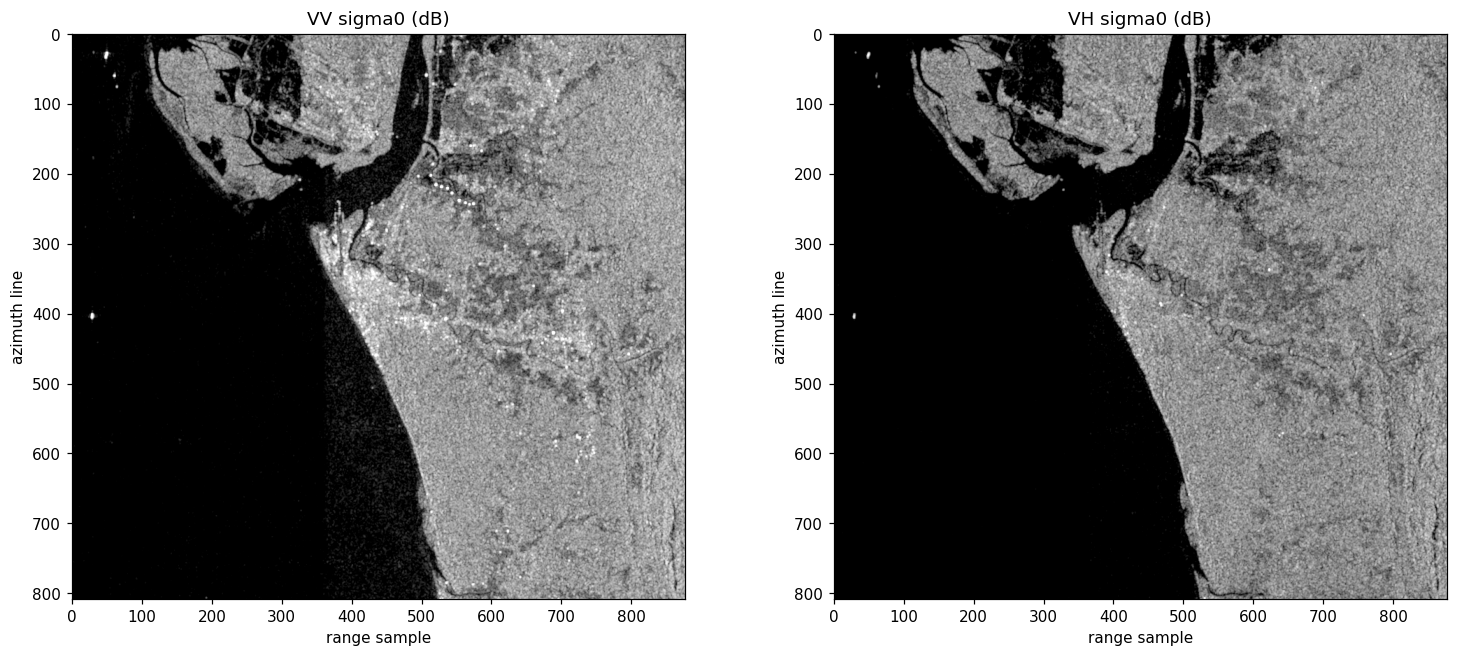

In [4]:
# Quick visual QC: display the calibrated sigma0 (dB) for VV and VH side by side.

# 1. One row of two panels, VV on the left and VH on the right.
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
# 2. VV uses a -25 to 0 dB stretch, typical for co-pol land/water backscatter.
axes[0].imshow(s1.to_db(sigma0["VV"]), cmap="gray", vmin=-25, vmax=0)
axes[0].set_title("VV sigma0 (dB)")  # title
# 3. VH uses a lower -30 to -5 dB stretch, since cross-pol backscatter is systematically
#    weaker than co-pol over ordinary land and water targets.
axes[1].imshow(s1.to_db(sigma0["VH"]), cmap="gray", vmin=-30, vmax=-5)
axes[1].set_title("VH sigma0 (dB)")  # title
# 4. Label axes in the image's native radar geometry (range sample / azimuth line) -- this
#    data has not been geocoded to a map projection yet (that happens in Steps 6-7 below).
for ax in axes:
    ax.set_xlabel("range sample"); ax.set_ylabel("azimuth line")  # axis labels
plt.tight_layout()  # arrange

### Multilook and speckle filtering

A homogeneous patch (the darkest, most uniform block found in this crop -- likely calm water
or a smooth mudflat) gives a real equivalent-number-of-looks (ENL) estimate before and after
each step: plain 2x2 multilook (Step 4, block-averaging -- cheap, but halves resolution in
each direction) against the Refined Lee filter (Step 5, edge-preserving, same output
resolution as the input). On this real patch, ENL rises from about 5.8 (single look -- this
ScanSAR product's own ground processing already averages several looks together, so it starts
well above 1) to 8.2 after a plain 2x2 multilook and to 26 after Refined Lee -- Refined Lee's
edge-aware window reaches noticeably further than a flat 2x2 block while keeping the full
output resolution, visible in the point-target brightness (likely small boats) that survives
sharply in both the single-look and Refined Lee panels below but blurs in the multilooked
one.


homogeneous patch at (row 600, col 440), mean -23.5 dB
ENL: single-look sigma0 5.8, 2x2 multilook 8.2, Refined Lee 26.0


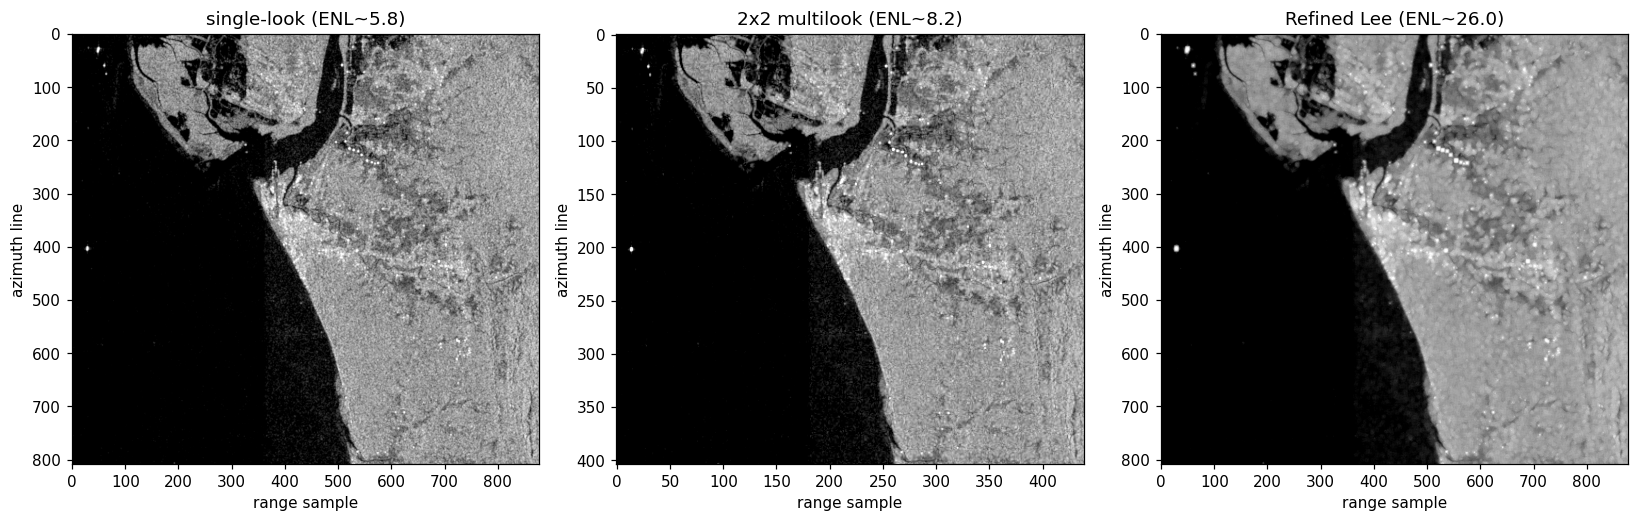

In [5]:
# Steps 4-5: compare plain 2x2 multilooking against the Refined Lee speckle filter, using a
# real homogeneous patch in this scene to estimate the equivalent number of looks (ENL)
# before and after each -- a stand-in for manually picking a calm-water or mudflat patch.

# 1. Scan the image in non-overlapping blocks and keep the one with the lowest coefficient
#    of variation (std/mean) among blocks at least 3 dB below the scene median -- i.e. the
#    most homogeneous dark block in this crop (lowest coefficient of variation among
#    blocks at least 3 dB below the scene median) -- a stand-in for a manually chosen water patch.
def homogeneous_patch(img, block=40, max_db=-18):
    best = None  # (coefficient of variation, row, column) of the best block so far
    for r in range(0, img.shape[0] - block, block):  # every block row
        for c in range(0, img.shape[1] - block, block):  # every block column
            blk = img[r:r + block, c:c + block]  # the block
            # skip blocks with gaps or brighter than max_db (not dark water)
            if not np.all(np.isfinite(blk)) or 10 * np.log10(blk.mean()) >= max_db:
                continue
            cv = blk.std() / blk.mean()  # coefficient of variation
            if best is None or cv < best[0]:  # keep the most homogeneous block
                best = (cv, r, c)  # store it
    return best[1], best[2]  # its row and column


# 2. Locate that patch's top-left row/col in the single-look VV sigma0 image.
pr, pc = homogeneous_patch(sigma0["VV"])


# 3. Helper to pull the same patch out of a *different* image that may have a different
#    shape than the reference (e.g. after 2x2 multilook halves each dimension) by rescaling
#    the patch's corner coordinates proportionally to that image's resolution.
def patch(img, ref_shape=sigma0["VV"].shape, r0=pr, c0=pc, size=40):
    # Rescale the patch's corners for an image at a different resolution (e.g. after multilook).
    ry, rx = img.shape[0] / ref_shape[0], img.shape[1] / ref_shape[1]
    # the same patch on a grid of a different size
    return img[int(r0 * ry):int((r0 + size) * ry), int(c0 * rx):int((c0 + size) * rx)]


# 4. Step 4: plain 2x2 block-average multilook. Step 5: Refined Lee speckle filter, seeded
#    with an ENL estimate from the same homogeneous patch (Refined Lee needs an estimate of
#    the input's ENL to set its adaptive edge-preserving weighting).
ml = s1.multilook(sigma0["VV"], (2, 2))
# Refined Lee filter using the measured ENL
rl = speckle.refined_lee(sigma0["VV"], enl=speckle.enl_estimate(patch(sigma0["VV"])))

# 5. Re-estimate ENL on the same patch location in each of the three images (single-look,
#    multilooked, Refined Lee) to quantify how much each step actually reduced speckle.
enl_raw = speckle.enl_estimate(patch(sigma0["VV"]))
enl_ml = speckle.enl_estimate(patch(ml))  # ENL after multilooking
enl_rl = speckle.enl_estimate(patch(rl))  # ENL after Refined Lee
# 6. Report the patch location/brightness and the three ENL values for direct comparison.
print(f"homogeneous patch at (row {pr}, col {pc}), mean {10 * np.log10(patch(sigma0['VV']).mean()):.1f} dB")
# ENL of the three versions
print(f"ENL: single-look sigma0 {enl_raw:.1f}, 2x2 multilook {enl_ml:.1f}, Refined Lee {enl_rl:.1f}")

# 7. Plot all three side by side, in dB with the same stretch as before, so speckle
#    reduction vs. resolution loss/retention can be compared visually across the three.
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
axes[0].imshow(s1.to_db(sigma0["VV"]), cmap="gray", vmin=-25, vmax=0)  # single-look sigma0
axes[0].set_title(f"single-look (ENL~{enl_raw:.1f})")  # title
axes[1].imshow(s1.to_db(ml), cmap="gray", vmin=-25, vmax=0)  # multilooked
axes[1].set_title(f"2x2 multilook (ENL~{enl_ml:.1f})")  # title
axes[2].imshow(s1.to_db(rl), cmap="gray", vmin=-25, vmax=0)  # Refined Lee
axes[2].set_title(f"Refined Lee (ENL~{enl_rl:.1f})")  # title
for ax in axes:  # for every panel
    ax.set_xlabel("range sample"); ax.set_ylabel("azimuth line")  # axis labels
plt.tight_layout()  # arrange

### Terrain flattening and terrain correction -- a known gap

Both need a DEM located against this product's own orbit state vectors and geolocation grid,
parsed from `product.xml` in RCM's own schema -- `geolattice` does not yet have that reader (the
same gap noted for RCM's compact-pol ARD product's own geometry layers). What *is* available,
and was already used by `07_03_01_01_sentinel1_grd.ipynb` for a raw source in the same
situation, is GCP/ellipsoid geocoding: `rioxarray`'s `.rio.reproject` warps the image straight
from its GCPs onto a map CRS via GDAL's GCP transformer, with no DEM at all. It is less
accurate over real terrain than range-Doppler terrain correction (no local relief
displacement correction), but it is a real, map-projected image rather than none.


geocoded (GCP/ellipsoid), UTM 46N: (374, 397), x 375603-415203, y 2350876-2388176


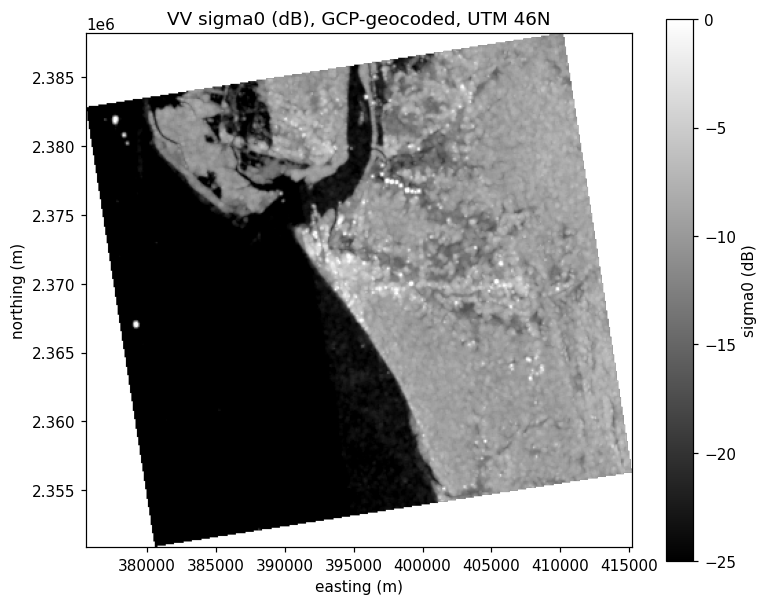

In [6]:
# Steps 6-7 fallback: geolattice cannot yet parse RCM's own orbit/geolocation-grid schema, so true
# terrain flattening and range-Doppler terrain correction are not available here. Instead,
# geocode the Refined-Lee image straight onto a UTM grid using its GCPs (no DEM involved) --
# the same fallback the Sentinel-1 GRD notebook uses for a raw source in the same situation.
from rasterio.control import GroundControlPoint
from rasterio.enums import Resampling  # resampling methods

# 1. The original GCPs are defined in the *full scene's* row/col space, but `rl` (the
#    Refined Lee output we're geocoding) is the cropped AOI window -- shift each GCP's
#    row/col by the crop's offset (ROW0/COL0) so they line up with the cropped array.
gcps_local = [GroundControlPoint(row=g.row - ROW0, col=g.col - COL0, x=g.x, y=g.y, z=g.z) for g in gcps]

# 2. Wrap the Refined Lee array in an xarray DataArray with plain pixel-index coordinates,
#    then attach the GCPs' own (geographic) CRS via write_crs -- rioxarray needs a CRS set
#    before it will reproject using ground control points.
da = xr.DataArray(rl, dims=("y", "x"), coords={"y": np.arange(rl.shape[0]), "x": np.arange(rl.shape[1])})
da = da.rio.write_crs(gcp_crs)  # attach the CRS of the GCPs
# 3. Reproject using the local GCPs as the warp control (GDAL's GCP transformer), targeting
#    UTM 46N at ~100 m resolution (matching this ScanSAR product's native resolution), with
#    bilinear resampling (appropriate for continuous backscatter values) and NaN nodata for
#    pixels that fall outside the input footprint.
geocoded = da.rio.reproject("EPSG:32646", gcps=gcps_local, resolution=100.0,   # UTM 46N; ~ScanSAR resolution
                            resampling=Resampling.bilinear, nodata=np.nan)
# 4. Report the geocoded array's shape and map extent (easting/northing) as a sanity check.
print(f"geocoded (GCP/ellipsoid), UTM 46N: {geocoded.shape}, "
      f"x {float(geocoded.x.min()):.0f}-{float(geocoded.x.max()):.0f}, "
      f"y {float(geocoded.y.min()):.0f}-{float(geocoded.y.max()):.0f}")

# 5. Plot the geocoded sigma0 in dB with a true map extent (easting/northing in metres)
#    rather than the arbitrary range-sample/azimuth-line axes used before geocoding.
fig, ax = plt.subplots(figsize=(8, 8))
# the geocoded image in dB, in map coordinates
im = ax.imshow(s1.to_db(geocoded.values), cmap="gray", vmin=-25, vmax=0,
              extent=[float(geocoded.x.min()), float(geocoded.x.max()),
                      float(geocoded.y.min()), float(geocoded.y.max())])
# title and axis labels
ax.set(title="VV sigma0 (dB), GCP-geocoded, UTM 46N", xlabel="easting (m)", ylabel="northing (m)")
ax.set_aspect("equal")  # equal scale
plt.colorbar(im, ax=ax, label="sigma0 (dB)", shrink=0.8)  # colour bar

## Takeaways and limitations

- Steps 1-5, 8 and 9 of the workflow above now run on a real RCM Level-1 GRD product:
  `geolattice.rsense.sar.radarsat`'s new `read_rcm_lut`/`interpolate_rcm_lut` (Step 3's gain) and
  `read_rcm_noise_levels`/`interpolate_rcm_noise` (Step 2's NESZ, correctly stitching this
  ScanSAR product's eight sub-beam segments) feed `calibrate_rcm`; multilook, Refined Lee and
  `to_db` are the same sensor-generic functions the Sentinel-1 notebooks use.
- **Steps 6-7 (terrain flattening, range-Doppler terrain correction) are not implemented for
  RCM** -- they need an orbit/geolocation-grid reader for `product.xml`'s own schema, which
  `geolattice` does not have. The GCP/ellipsoid geocoding above is the same fallback
  `07_03_01_01_sentinel1_grd.ipynb` used for a Sentinel-1 source in the identical situation,
  and carries the identical caveat: no local relief (layover/shadow/foreshortening)
  correction, so it should not be over-trusted in hilly terrain (this AOI's coastal plain is
  about as forgiving a case as that gets).
- The ScanSAR noise-level stitching takes the later (higher-pixel-range) of two overlapping
  beam segments at their seam rather than blending them -- a simplification worth knowing
  about if a seam artifact ever shows up in a wide-swath NESZ curve.

#### References

- Natural Resources Canada / CSA, *RADARSAT Constellation Mission Product Format
  Definition*, document RCM-SP-52-9092 (describes the ``lutSigma``/``lutBeta``/``lutGamma`` and
  ``noiseLevels`` XML schemas this notebook reads).
- Small, D. (2011). *Flattening gamma: Radiometric terrain correction for SAR imagery.* IEEE
  TGRS, 49(8), 3081-3093. (Step 6, not yet implemented for RCM)
- Lee, J. S. (1981). *Speckle analysis and smoothing of synthetic aperture radar images.*
  Computer Graphics and Image Processing, 17(1), 24-32.
- Lopes, A., Touzi, R., & Nezry, E. (1990). *Adaptive speckle filters and scene heterogeneity.*
  IEEE TGRS, 28(6), 992-1000.
